# Análisis administrativo de BaseUnificada

Responde una pregunta general, tres específicas y una línea adicional de segmentos.
Usa la entrega validada y los criterios de elegibilidad del notebook 03.
El proceso de limpieza permanece en el notebook 02. No se modifica el Excel,
PostgreSQL ni Drive. El dashboard se construirá después con las mismas definiciones.

Los porcentajes describen registros, no personas independientes confirmadas.
No se fuerza una conclusión favorable a un canal o segmento. No se aplican pruebas
de significación de manera automática y no se identifica no significación con equivalencia.
La marca de menos de 30 registros es prudencia visual, no una garantía de precisión.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from analitica_admisiones.analisis_administrativo import AnalisisAdministrativo

analisis = AnalisisAdministrativo(ROOT)
display(pd.DataFrame([{'Registros':len(analisis.base), 'Columnas':len(analisis.base.columns),
    'Unidad':'Registro de solicitud de origen', 'SHA256 del Excel':analisis.input_sha}]))

,Registros,Columnas,Unidad,SHA256 del Excel
0,5500,18,Registro de solicitud de origen,561b084b0501f2dedefe7286e2fa714242508f2f65301d...


## 1. Pregunta general y demanda por programa

¿Cómo se distribuyen las solicitudes por programa, modalidad y canal, y qué se observa
en los estados del proceso? Las cantidades usan los 5.500 registros. Sin información
es una etiqueta para presentar programas ausentes y no una imputación del dato maestro.
Los periodos representan semestres de ingreso. No se deducen desde la fecha de solicitud.

In [2]:
display(analisis.volumen())
for nombre in ['programa','modalidad','canal_captacion','estado_proceso','programa_periodo_academico']:
    display(Markdown('### ' + nombre.replace('_',' ')))
    display(analisis.tables[nombre])

,registros,matriculados,proporcion_matriculado_pct,puntajes_informados,importes_informados,programas_identificados,programa_sin_informacion
0,5500,1179,21.436364,5254,4580,7,26


### programa

,programa,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
2,Derecho,1233,251,1168,1024,22.418182,20.356853,-1.079510,94.728305,83.049473,False,5500
3,Especialización en Data Analytics,1216,257,1168,1022,22.109091,21.134868,-0.301495,96.052632,84.046053,False,5500
5,Ingeniería de Sistemas,630,127,608,517,11.454545,20.158730,-1.277633,96.507937,82.063492,False,5500
1,Contaduría Pública,613,145,586,516,11.145455,23.654160,2.217796,95.595432,84.176183,False,5500
4,Especialización en Gerencia,605,117,578,496,11.000000,19.338843,-2.097521,95.537190,81.983471,False,5500
6,Psicología,595,136,571,491,10.818182,22.857143,1.420779,95.966387,82.521008,False,5500
0,Administración de Empresas,582,139,551,493,10.581818,23.883162,2.446798,94.673540,84.707904,False,5500
7,Sin información,26,7,24,21,0.472727,26.923077,5.486713,92.307692,80.769231,True,5500


### modalidad

,modalidad,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
1,Presencial,2192,444,2102,1830,39.854545,20.255474,-1.180889,95.894161,83.485401,False,5500
2,Virtual,2183,486,2076,1822,39.690909,22.262941,0.826577,95.098488,83.463124,False,5500
0,Híbrida,1125,249,1076,928,20.454545,22.133333,0.696970,95.644444,82.488889,False,5500


### canal captacion

,canal_captacion,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
1,Feria universitaria,941,194,903,789,17.109091,20.616366,-0.819998,95.961743,83.846971,False,5500
2,Instagram,939,224,899,779,17.072727,23.855165,2.418801,95.740149,82.960596,False,5500
0,Correo,926,206,883,776,16.836364,22.246220,0.809857,95.356371,83.801296,False,5500
4,Referido,915,180,862,749,16.636364,19.672131,-1.764232,94.207650,81.857923,False,5500
5,Web institucional,891,193,853,742,16.200000,21.661055,0.224691,95.735129,83.277217,False,5500
3,Landing page,888,182,854,745,16.145455,20.495495,-0.940868,96.171171,83.896396,False,5500


### estado proceso

,estado_proceso,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
0,Admitido,1822,0,1745,1501,33.127273,0.0,-21.436364,95.773875,82.381998,False,5500
3,Matriculado,1179,1179,1124,986,21.436364,100.0,78.563636,95.335030,83.630195,False,5500
1,Documentación pendiente,638,0,599,537,11.600000,0.0,-21.436364,93.887147,84.169279,False,5500
2,Inscrito,630,0,600,525,11.454545,0.0,-21.436364,95.238095,83.333333,False,5500
4,No admitido,617,0,598,519,11.218182,0.0,-21.436364,96.920583,84.116694,False,5500
5,Retirado,614,0,588,512,11.163636,0.0,-21.436364,95.765472,83.387622,False,5500


### programa periodo academico

,programa,periodo_academico,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito,denominador_periodo,participacion_dentro_periodo_pct
0,Administración de Empresas,20252,106,24,106,90,1.927273,22.641509,1.205146,100.000000,84.905660,False,5500,1071,9.897292
1,Administración de Empresas,20261,241,67,229,206,4.381818,27.800830,6.364466,95.020747,85.477178,False,5500,2246,10.730187
2,Administración de Empresas,20262,235,48,216,197,4.272727,20.425532,-1.010832,91.914894,83.829787,False,5500,2183,10.765002
3,Contaduría Pública,20252,130,21,123,108,2.363636,16.153846,-5.282517,94.615385,83.076923,False,5500,1071,12.138189
4,Contaduría Pública,20261,244,67,235,206,4.436364,27.459016,6.022653,96.311475,84.426230,False,5500,2246,10.863758
5,Contaduría Pública,20262,239,57,228,202,4.345455,23.849372,2.413009,95.397490,84.518828,False,5500,2183,10.948236
6,Derecho,20252,230,48,222,194,4.181818,20.869565,-0.566798,96.521739,84.347826,False,5500,1071,21.475257
7,Derecho,20261,518,103,486,423,9.418182,19.884170,-1.552194,93.822394,81.660232,False,5500,2246,23.063224
8,Derecho,20262,485,100,460,407,8.818182,20.618557,-0.817807,94.845361,83.917526,False,5500,2183,22.217132
9,Especialización en Data Analytics,20252,231,55,223,188,4.200000,23.809524,2.373160,96.536797,81.385281,False,5500,1071,21.568627


## 2. Canales comparables

Se muestran las proporciones brutas y una estandarización descriptiva con pesos comunes
de programa, modalidad y periodo. Solo se incluyen estratos donde están los seis canales.
La tabla informa su cobertura y las celdas pequeñas. No es una comparación causal ni
una tasa definitiva de conversión. La igualdad de composición no resuelve la dependencia
entre solicitudes del mismo aspirante o los candidatos Oracle.

In [3]:
display(analisis.canales_comparables())
display(analisis.tables['pesos_estratos_comunes'].head(10))

,canal_captacion,registros_totales,proporcion_bruta_pct,registros_soporte_comun,proporcion_bruta_soporte_pct,proporcion_estandarizada_descriptiva_pct,estratos_comunes,menor_celda,celdas_menores_30,cobertura_soporte_del_canal_pct
2,Instagram,939,23.855165,935,23.743316,23.417924,63,2,57,99.574015
0,Correo,926,22.246220,921,22.041260,22.916120,63,2,58,99.460043
5,Web institucional,891,21.661055,886,21.670429,21.424830,63,2,56,99.438833
1,Feria universitaria,941,20.616366,935,20.748663,20.586683,63,1,58,99.362380
3,Landing page,888,20.495495,884,20.475113,20.544017,63,1,58,99.549550
4,Referido,915,19.672131,913,19.715225,20.218522,63,1,55,99.781421


,programa,modalidad,periodo_academico,peso_comun
0,Administración de Empresas,Híbrida,20252,0.003106
1,Administración de Empresas,Híbrida,20261,0.010047
2,Administración de Empresas,Híbrida,20262,0.008769
3,Administración de Empresas,Presencial,20252,0.008586
4,Administración de Empresas,Presencial,20261,0.016076
5,Administración de Empresas,Presencial,20262,0.015163
6,Administración de Empresas,Virtual,20252,0.007673
7,Administración de Empresas,Virtual,20261,0.017903
8,Administración de Empresas,Virtual,20262,0.018999
9,Contaduría Pública,Híbrida,20252,0.004932


## 3. Documentación, asesor, puntajes, tiempos y recurrencia

La tercera pregunta específica del informe se responde con distribución de estados
según documentación y asesor, incluidos sus cruces por programa, modalidad y periodo.
El intervalo entre solicitud y matrícula es un complemento, no tiempo por etapa.
Las franjas de puntaje son descriptivas y no representan reglas institucionales de aprobación.
Los códigos se cuentan por origen. La recurrencia no se declara duplicado automáticamente.

In [4]:
display(analisis.seguimiento())
for nombre in ['documentos_completos','documentacion_estado','asesor',
               'franja_puntaje_estados_porcentajes','intervalos_por_documentacion',
               'recurrencia_codigos','importes_por_programa']:
    display(Markdown('### ' + nombre.replace('_',' ')))
    display(analisis.tables[nombre])

,estado_proceso,informados,promedio,mediana,minimo,maximo,cuartil_1,cuartil_3,registros,cobertura_puntaje_pct
0,Admitido,1745,70.212607,70.0,40.0,100.0,56.0,85.00,1822,95.773875
1,Documentación pendiente,599,70.592654,70.0,40.0,100.0,56.0,85.00,638,93.887147
2,Inscrito,600,70.580000,70.0,40.0,100.0,55.0,86.25,630,95.238095
3,Matriculado,1124,71.230427,71.0,40.0,100.0,57.0,87.00,1179,95.335030
4,No admitido,598,67.797659,67.0,40.0,100.0,52.0,83.00,617,96.920583
5,Retirado,588,68.692177,69.0,40.0,100.0,52.0,85.00,614,95.765472


### documentos completos

,documentos_completos,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
0,No,1098,256,1057,948,19.963636,23.315118,1.878755,96.265938,86.338798,False,5500
1,Pendiente,1117,258,1067,918,20.309091,23.097583,1.661219,95.523724,82.184423,False,5500
2,Sí,3285,665,3130,2714,59.727273,20.243531,-1.192832,95.281583,82.617960,False,5500


### documentacion estado

estado_proceso,documentos_completos,Admitido,Documentación pendiente,Inscrito,Matriculado,No admitido,Retirado
0,No,340,122,126,256,133,121
1,Pendiente,388,123,117,258,111,120
2,Sí,1094,393,387,665,373,373


### asesor

... (5 outputs left out)

### recurrencia codigos

,fuente_origen,solicitudes_por_codigo,codigos,registros,denominador_codigos_origen
0,Oracle,1,500,500,500
1,Principal,1,1561,1561,2924
2,Principal,2,902,1804,2924
3,Principal,3,343,1029,2924
4,Principal,4,85,340,2924
5,Principal,5,25,125,2924
6,Principal,6,5,30,2924
7,Principal,7,3,21,2924


### importes por programa

,programa,informados,importes_distintos,minimo,maximo,promedio,mediana,registros,cobertura_importe_pct
0,Administración de Empresas,493,5,1800000.0,3500000.0,2.631034e+06,2500000.0,582,84.707904
1,Contaduría Pública,516,5,1800000.0,3500000.0,2.638178e+06,2500000.0,613,84.176183
2,Derecho,1024,5,1800000.0,3500000.0,2.598242e+06,2500000.0,1233,83.049473
3,Especialización en Data Analytics,1022,5,1800000.0,3500000.0,2.628474e+06,2500000.0,1216,84.046053
4,Especialización en Gerencia,496,5,1800000.0,3500000.0,2.593548e+06,2500000.0,605,81.983471
5,Ingeniería de Sistemas,517,5,1800000.0,3500000.0,2.611992e+06,2500000.0,630,82.063492
6,Psicología,491,5,1800000.0,3500000.0,2.590835e+06,2500000.0,595,82.521008
7,Sin información,21,5,1800000.0,3500000.0,2.438095e+06,2200000.0,26,80.769231


## 4. Segmentos de interés y sensibilidad

Las combinaciones de ciudad, programa y modalidad se ordenan por volumen, sin afirmar
que sean nichos de mercado confirmados. Los cruces finos por canal y periodo se guardan
completos con marca de grupos pequeños. Se comprueba un escenario hipotético de contar
una vez los 49 pares compatibles. Las 500 filas Oracle permanecen en la entrega.
No se resuelve con ese escenario la identidad de los otros 451 pares.

In [5]:
display(analisis.segmentos())
display(analisis.tables['segmentos_completos'].describe(include='all'))

,ciudad_residencia,programa,modalidad,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
8,Bogotá,Derecho,Virtual,133,21,123,102,2.418182,15.789474,-5.646890,92.481203,76.691729,False,5500
34,Cali,Especialización en Data Analytics,Presencial,122,28,120,101,2.218182,22.950820,1.514456,98.360656,82.786885,False,5500
7,Bogotá,Derecho,Presencial,121,23,119,101,2.200000,19.008264,-2.428099,98.347107,83.471074,False,5500
32,Cali,Derecho,Virtual,120,23,114,103,2.181818,19.166667,-2.269697,95.000000,85.833333,False,5500
35,Cali,Especialización en Data Analytics,Virtual,120,25,116,108,2.181818,20.833333,-0.603030,96.666667,90.000000,False,5500
10,Bogotá,Especialización en Data Analytics,Presencial,119,28,109,94,2.163636,23.529412,2.093048,91.596639,78.991597,False,5500
100,Popayán,Derecho,Virtual,106,29,102,88,1.927273,27.358491,5.922127,96.226415,83.018868,False,5500
31,Cali,Derecho,Presencial,101,23,95,84,1.836364,22.772277,1.335914,94.059406,83.168317,False,5500
99,Popayán,Derecho,Presencial,101,13,95,80,1.836364,12.871287,-8.565077,94.059406,79.207921,False,5500
103,Popayán,Especialización en Data Analytics,Virtual,90,14,84,73,1.636364,15.555556,-5.880808,93.333333,81.111111,False,5500


,ciudad_residencia,programa,modalidad,registros,matriculados,puntajes_informados,importes_informados,participacion_registros_pct,proporcion_matriculado_pct,diferencia_pp_frente_total_ambito,cobertura_puntaje_pct,cobertura_importe_pct,grupo_pequeno,denominador_ambito
count,138,138,138,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138,138.0
unique,6,8,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,Bogotá,Derecho,Presencial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
freq,24,18,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77,NaN
mean,NaN,NaN,NaN,39.855072,8.543478,38.072464,33.188406,0.724638,21.627093,0.190729,95.498016,83.261742,NaN,5500.0
std,NaN,NaN,NaN,28.197052,6.333919,26.918812,23.681756,0.512674,12.694326,12.694326,4.844459,8.911391,NaN,0.0
min,NaN,NaN,NaN,1.000000,0.000000,1.000000,1.000000,0.018182,0.000000,-21.436364,66.666667,50.000000,NaN,5500.0
25%,NaN,NaN,NaN,22.000000,4.000000,21.000000,18.000000,0.400000,15.810359,-5.626004,93.248588,78.958425,NaN,5500.0
50%,NaN,NaN,NaN,33.000000,8.000000,31.000000,26.000000,0.600000,20.761494,-0.674869,96.295026,83.333333,NaN,5500.0
75%,NaN,NaN,NaN,53.750000,12.000000,51.000000,46.000000,0.977273,25.925926,4.489562,100.000000,89.090909,NaN,5500.0


## 5. Qué cambió después de limpiar y de incorporar fuentes

Primero se alinean categorías sobre las mismas 5.040 filas originales. Después se
compara esa fuente con sus 5.000 registros conciliados. Finalmente se incorporan los
500 registros Oracle. El aumento de fuente no se presenta como efecto de limpieza
o crecimiento institucional. Los archivos originales se mantienen intactos.

In [6]:
display(analisis.antes_despues())
display(analisis.tables['evolucion_cantidades'])
display(analisis.tables['antes_despues_ambitos_separados'])

,columna,etiquetas_recibidas,categorias_agrupadas,filas_en_ambos
0,programa,10,8,5040
1,modalidad,5,3,5040
2,estado_proceso,9,6,5040


,etapa,registros,interpretacion
0,Original,5040,Fuente original con repeticiones
1,Principal conciliada,5000,38 repeticiones exactas y dos parciales consol...
2,Integrada,5500,"Se incorporan 500 registros Oracle, no es efec..."


,variable,categoria,etapa,registros,denominador,porcentaje
0,programa,Especialización en Data Analytics,Original con etiquetas alineadas,1136,5040,22.539683
1,programa,Derecho,Original con etiquetas alineadas,1122,5040,22.261905
2,programa,Ingeniería de Sistemas,Original con etiquetas alineadas,572,5040,11.349206
3,programa,Contaduría Pública,Original con etiquetas alineadas,558,5040,11.071429
4,programa,Especialización en Gerencia,Original con etiquetas alineadas,554,5040,10.992063
...,...,...,...,...,...,...
64,estado_proceso,Matriculado,Integrada con Oracle,1179,5500,21.436364
65,estado_proceso,Documentación pendiente,Integrada con Oracle,638,5500,11.600000
66,estado_proceso,Inscrito,Integrada con Oracle,630,5500,11.454545
67,estado_proceso,No admitido,Integrada con Oracle,617,5500,11.218182


## 6. Visualizaciones

Cada figura responde a una pregunta y conserva la unidad y cobertura. La guía separa
las tres figuras principales del material de apoyo. Los importes no se usan para
deducir tarifas o recaudo y los estados no se dibujan como transiciones de un embudo.

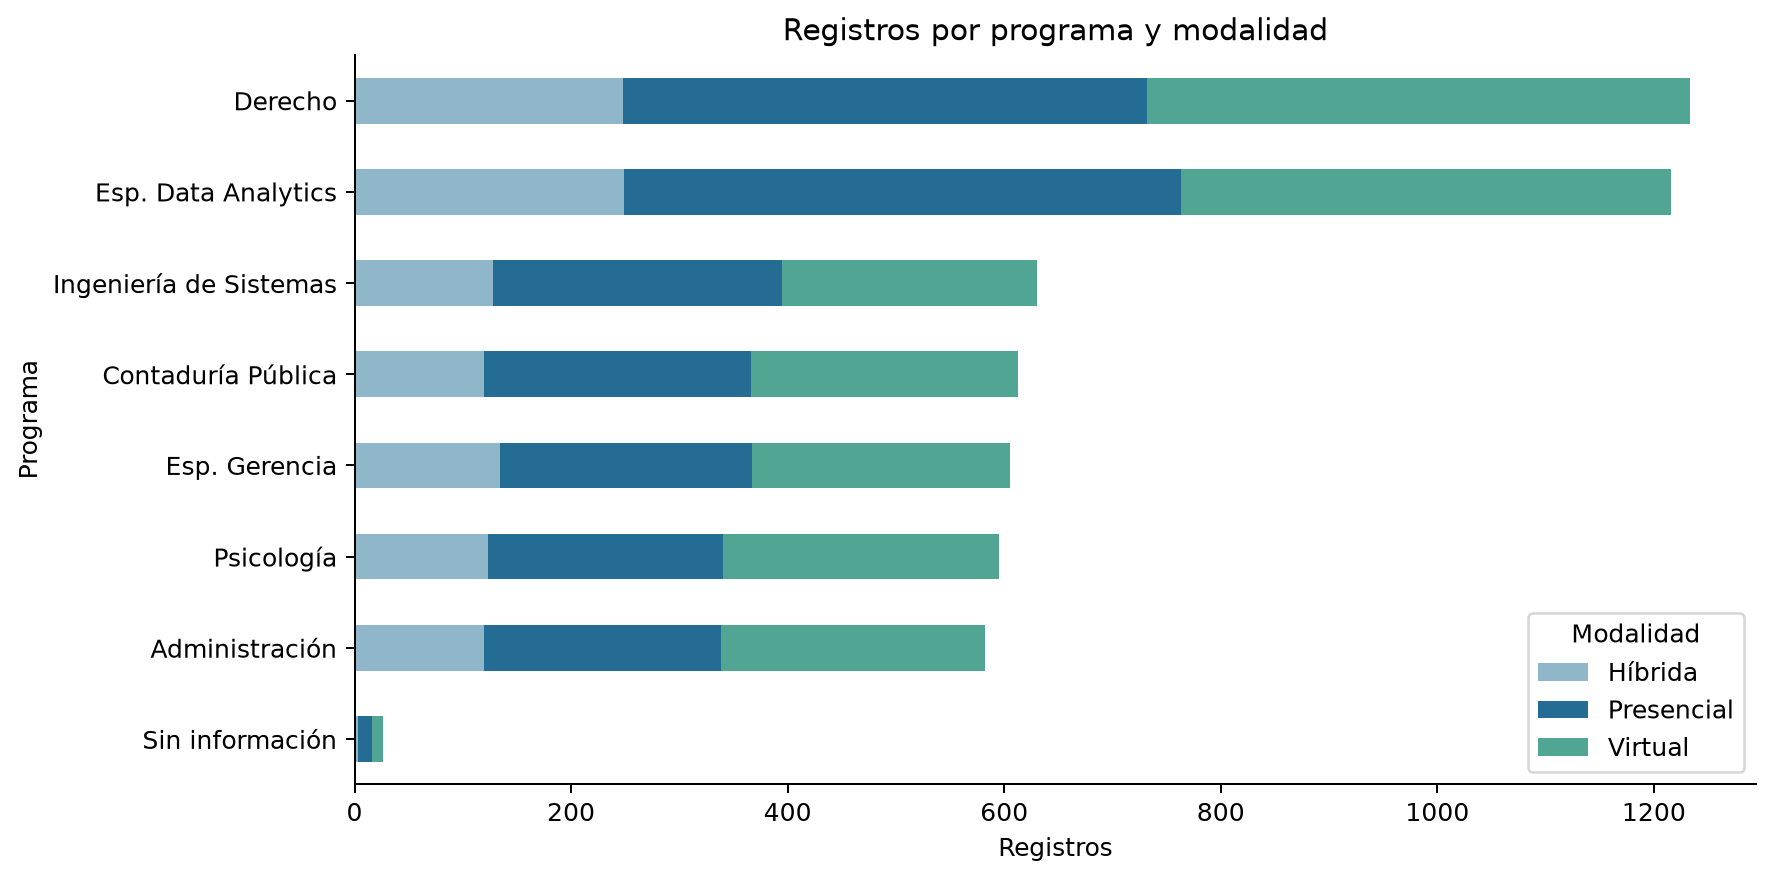

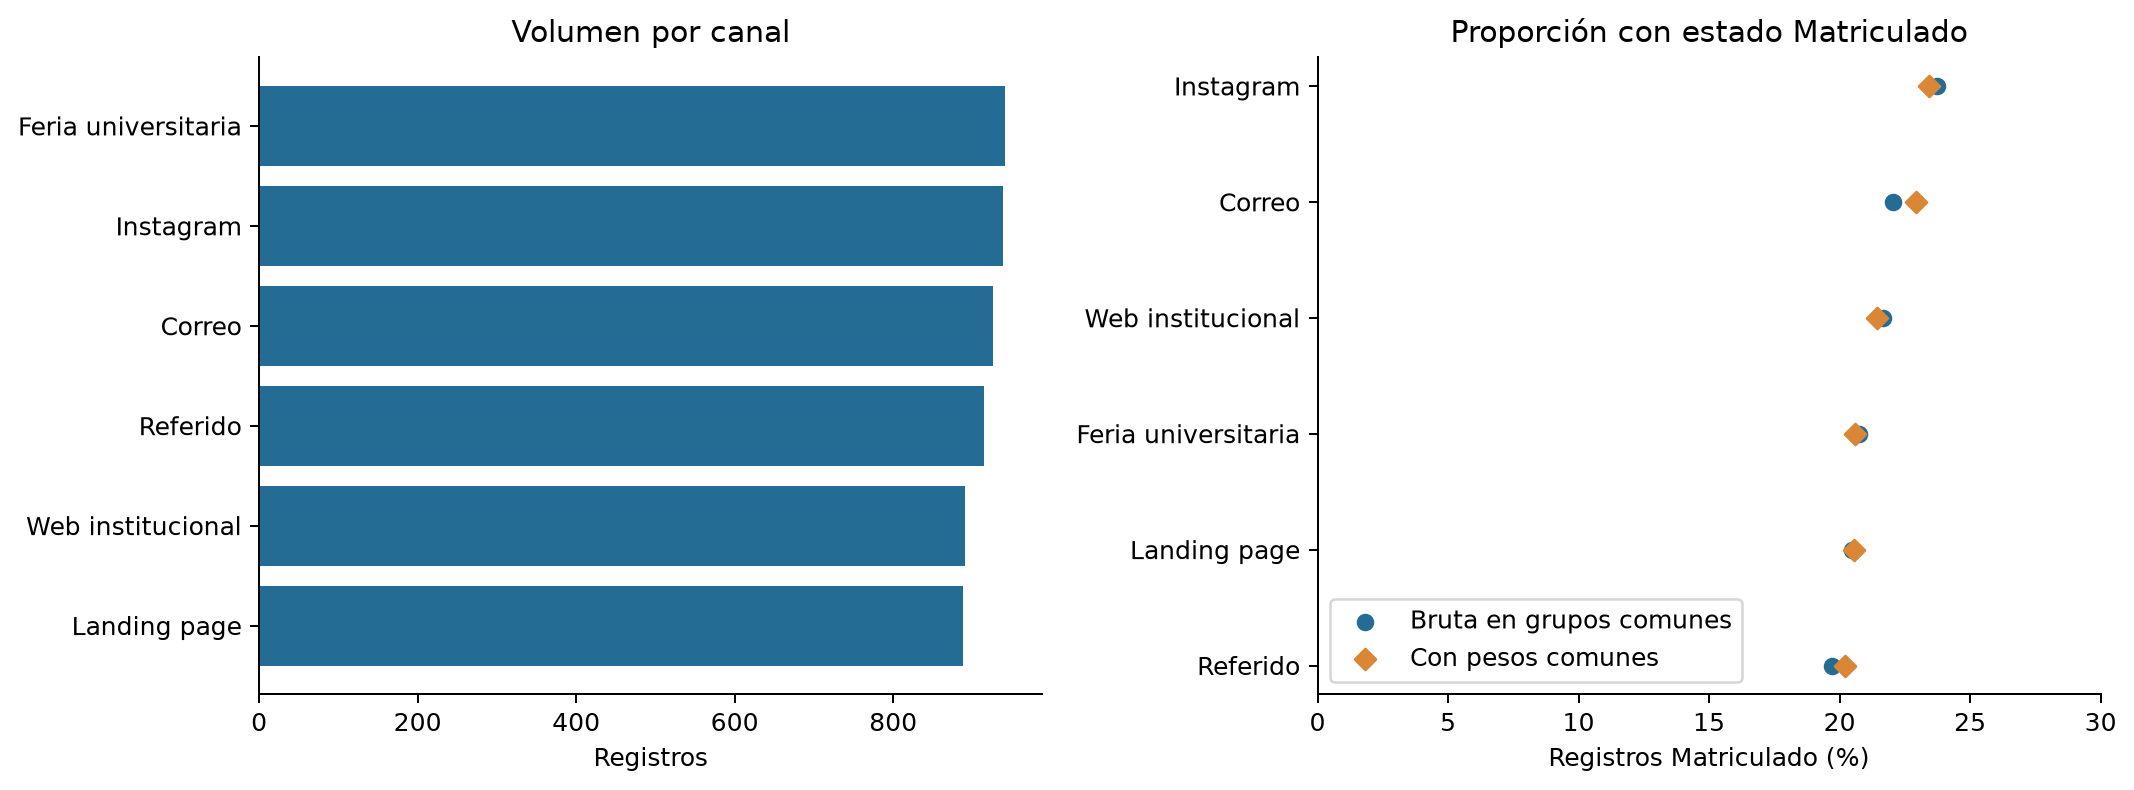

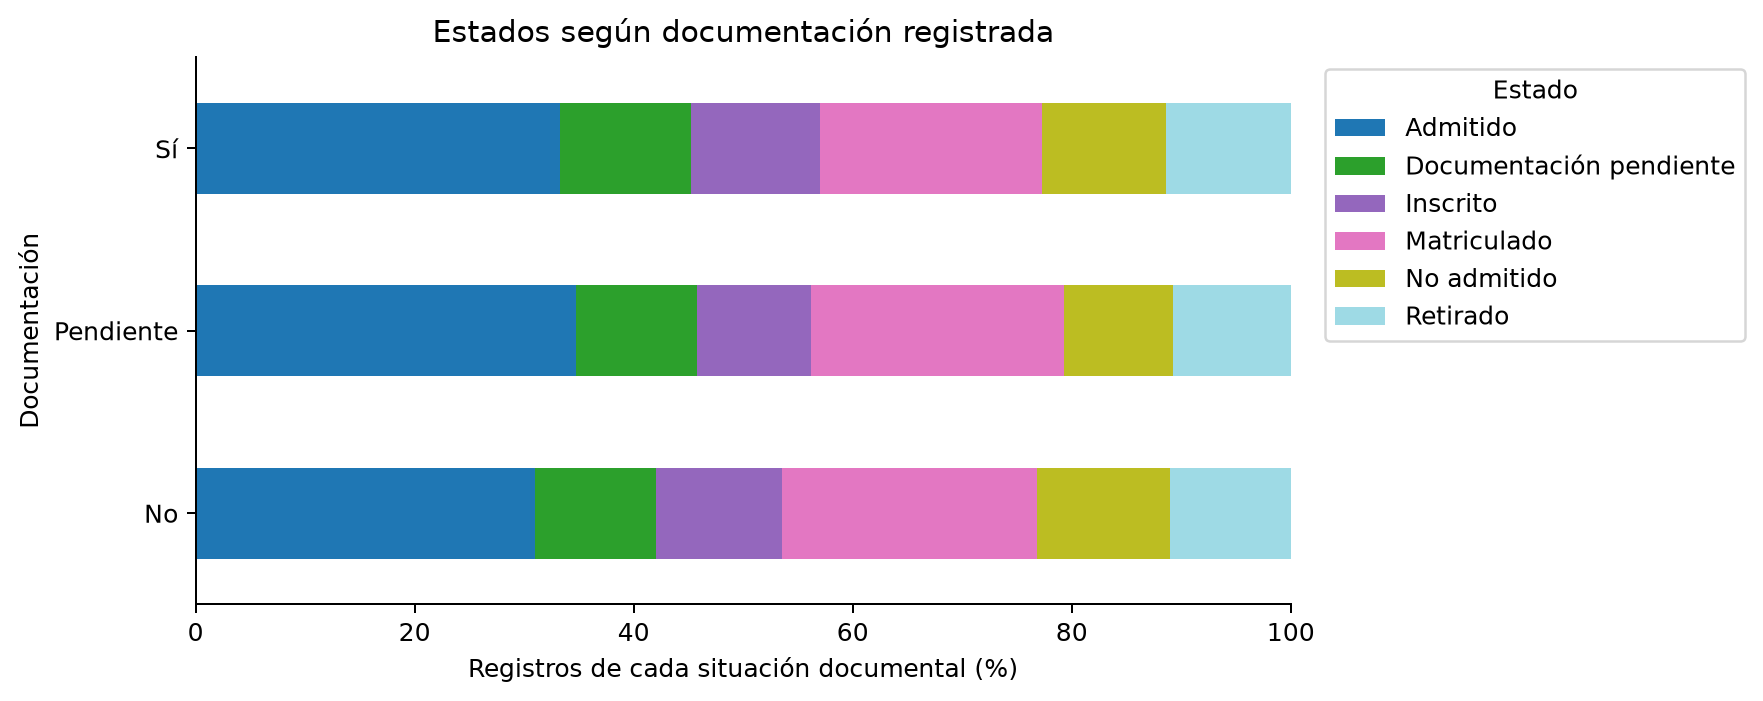

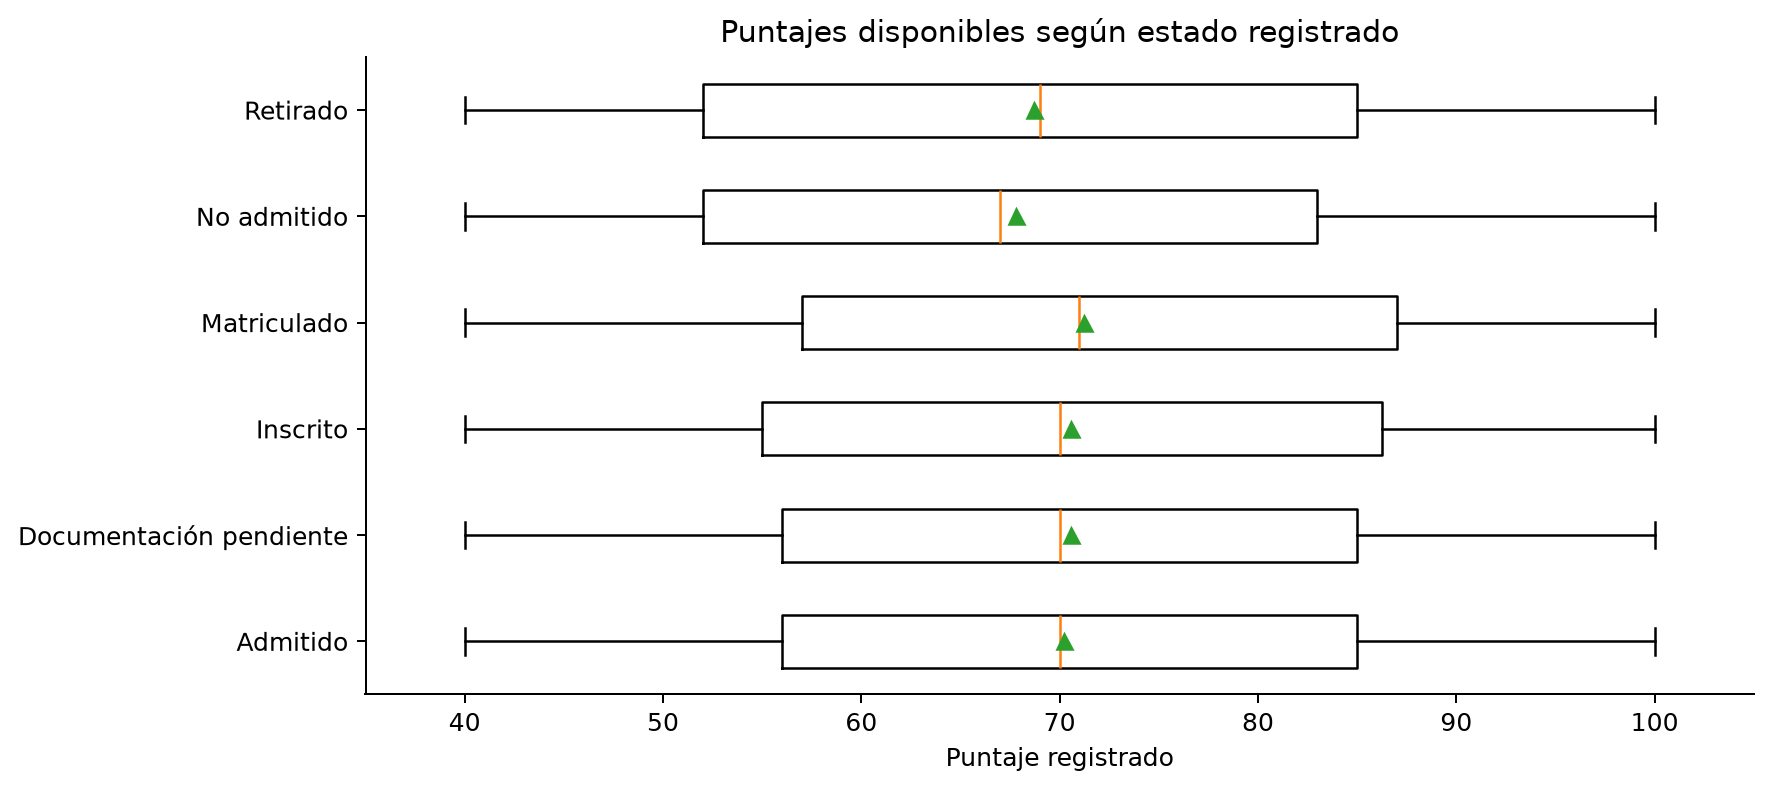

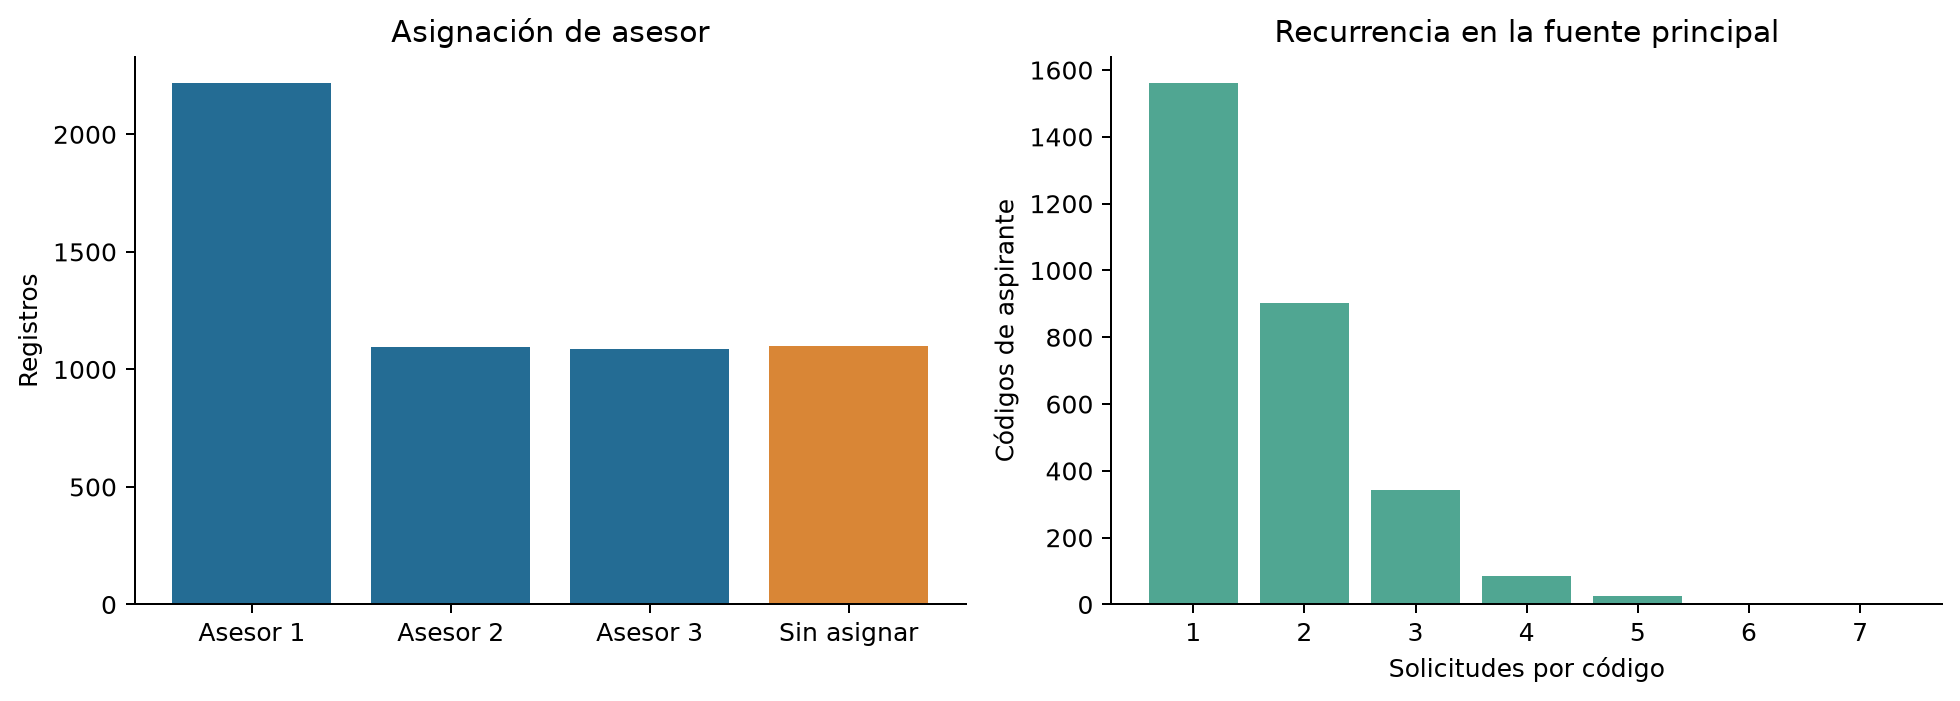

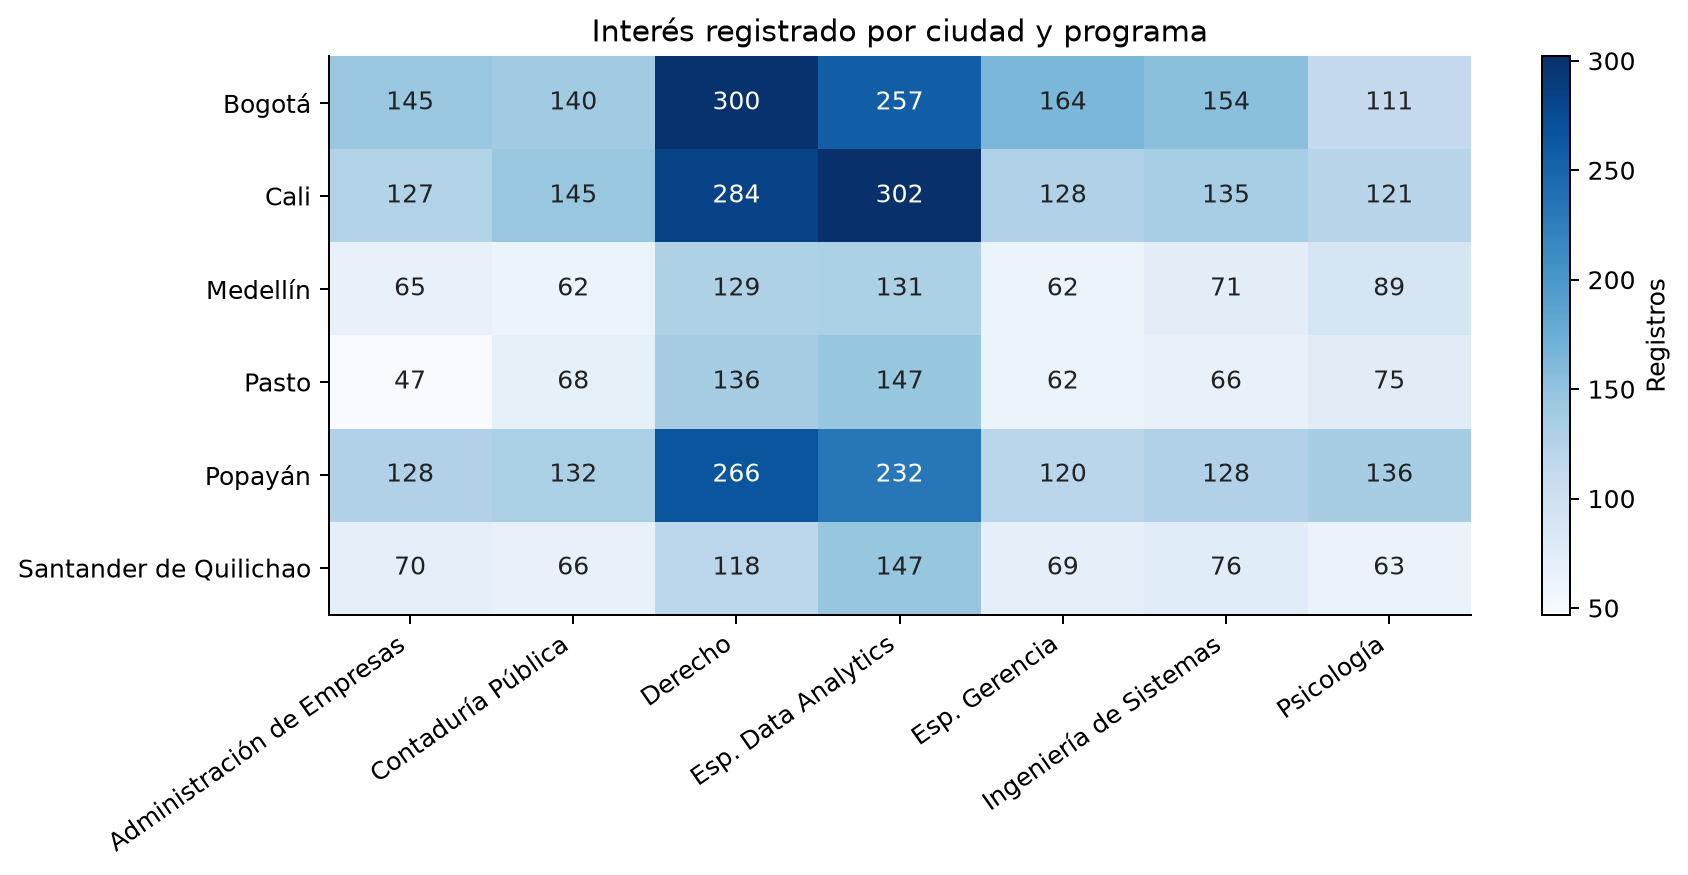

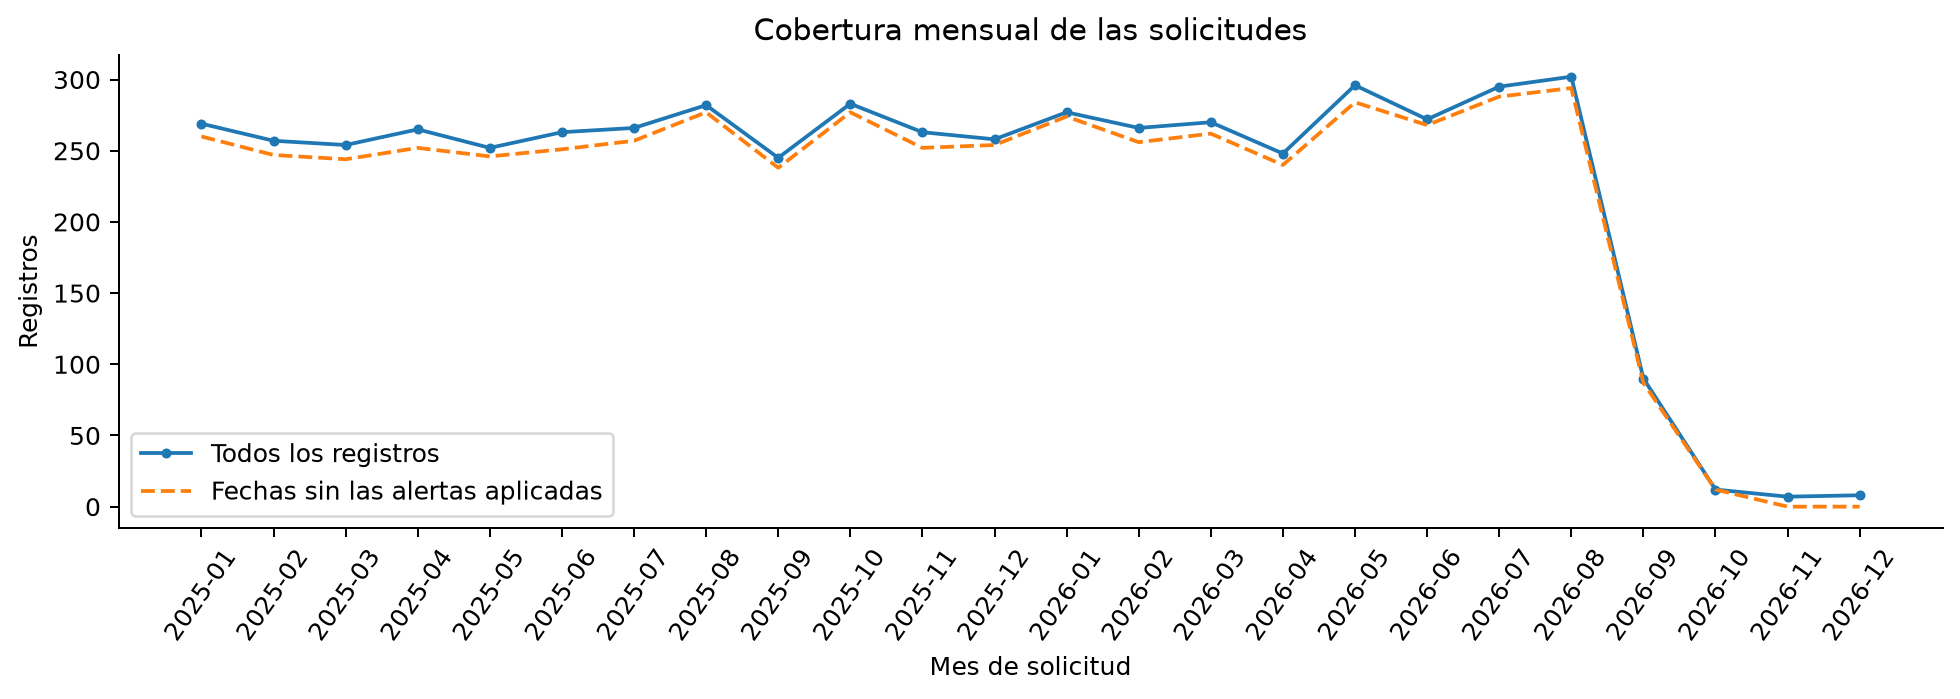

In [7]:
for figura in analisis.graficar():
    display(Image(filename=str(analisis.fig / figura['archivo'])))

## 7. Interpretación y acciones propuestas

Cada hallazgo distingue hecho, acción y límite. Los responsables son propuestas
funcionales y no asignaciones realizadas. Las metas se definirán después de revisar
capacidad, costos y una línea de referencia. El informe en Drive no se edita automáticamente.

In [8]:
display(analisis.redactar())
display(analisis.tables['acciones_propuestas'])
display(Markdown((analisis.out / 'seccion_informe_drive.md').read_text()))

,codigo,hallazgo,hecho_observado,accion_propuesta,limite
0,H01,Concentración de interés registrado,Derecho y Especialización en Data Analytics re...,"Revisar capacidad, mensajes y atención para la...",Las solicitudes no representan todo el mercado...
1,H02,Diferencias observadas entre canales,"Instagram presenta 23,86 % con estado Matricul...","Comparar campañas piloto dentro de programas, ...",Las celdas pequeñas y la composición limitan l...
2,H03,Coherencia documental por revisar,514 de 1.179 registros Matriculado tienen docu...,Revisar las reglas y actualización coordinada ...,No se conoce la fecha de actualización de cada...
3,H04,Puntajes y estados con información parcial,"Promedio 70,21 en Admitido y 67,80 en No admit...",Examinar distribución y reglas de admisión ant...,Una diferencia de promedios no reconstruye la ...
4,H05,Asignación y recurrencia requieren dos unidade...,"1.101 registros, 20,02 %, figuran Sin asignar....",Revisar asignación y seguimiento por solicitud...,La recurrencia puede ser legítima. No se atrib...
5,H06,"Segmentos para validar, no nichos confirmados","La matriz ciudad, programa y modalidad identif...",Seleccionar combinaciones con volumen suficien...,La marca de 30 no prueba precisión. El escenar...
6,H07,Importes insuficientes para deducir tarifas po...,Los siete programas identificados presentan ci...,Mantener los importes como contexto y contrast...,"No acredita pagos, recaudo o tarifas oficiales..."


,evidencia,decision_o_accion,responsable_propuesto,como_evaluar,estado
0,H03,Revisar los 514 casos documentales de Matricul...,Admisiones y gestión documental,"Casos revisados, reglas aclaradas y registros ...","Propuesta, sin ejecutar"
1,H05,Revisar los 1.101 registros Sin asignar y defi...,Coordinación de admisiones,Registros con asignación validada y fecha de a...,"Propuesta, sin ejecutar"
2,H01 y H06,Seleccionar segmentos con volumen y capacidad ...,Mercadeo y coordinación académica,"Solicitudes identificadas por campaña, seguimi...",Hipótesis para evaluar
3,H02,Comparar canales con igual oferta y seguimient...,Mercadeo y admisiones,Resultados con denominadores comparables y gas...,"Propuesta, sin ejecutar"
4,H04,Contrastar puntajes y decisiones con las regla...,Comité de admisiones,"Casos explicados por criterio, programa y periodo","Propuesta, sin ejecutar"
5,H05 y H07,"Mejorar identificación entre fuentes, registro...",Gestión de datos y responsables de sistemas,"Correspondencias confirmadas, eventos con fech...",Requiere registro futuro


# Análisis descriptivo de la base integrada

La base integrada reúne 5.500 registros de solicitudes. El análisis permite reconocer dónde se concentra el interés registrado y qué aspectos del seguimiento requieren atención. Los resultados corresponden a registros disponibles y no deben interpretarse como aspirantes únicos o tasas definitivas de conversión.

Derecho y Especialización en Data Analytics reúnen 2.449 registros, equivalentes al 44,53 % del total. Presencial representa el 39,85 %, Virtual el 39,69 % e Híbrida el 20,45 %. Estas participaciones orientan la revisión de la oferta y la atención, sin demostrar por sí solas la demanda de todo el mercado.

[Insertar aquí el gráfico 01_programas_modalidades.png.]

Los canales presentan volúmenes cercanos. Instagram registra una proporción Matriculado de 23,86 % y Referido de 19,67 %. La amplitud entre canales es 4,18 puntos porcentuales en la base completa. En el soporte comparable es 4,03 puntos antes de ponderar y 3,20 puntos con pesos comunes por programa, modalidad y periodo. Esta comparación utiliza 5.474 registros en grupos con presencia de todos los canales y contiene celdas pequeñas. Por ello, sus resultados justifican profundizar la comparación, pero no reasignar presupuesto únicamente por el porcentaje observado.

[Insertar aquí el gráfico 02_canales_comparables.png.]

El estado Matriculado reúne 1.179 registros, equivalentes al 21,44 %. Dentro de ellos, 514 tienen documentación registrada como No o Pendiente. Además, 393 registros con estado Documentación pendiente señalan documentos completos. Se recomienda revisar las reglas y la actualización de ambas columnas antes de interpretar estas diferencias como incumplimientos. La base no contiene un historial que permita reconstruir el avance de cada aspirante.

[Insertar aquí el gráfico 03_documentacion_estados.png.]

El promedio del puntaje disponible es 70,21 en Admitido y 67,80 en No admitido. Esta diferencia requiere contrastarse con la distribución de puntajes y los criterios de admisión, sin asumir que el promedio explica las decisiones. Los importes se mantienen como contexto económico. Los siete programas presentan cinco valores y la misma mediana de 2.500.000 COP, con 920 importes ausentes, por lo que no se deducen tarifas ni ingresos recibidos.

Los intervalos entre el primer y tercer cuartil de ambos estados se superponen. En los intervalos temporales aptos, las medianas por documentación son 33 días para Sí, 34 para No y 33 para Pendiente. Describen únicamente los casos con ambas fechas que cumplen los controles y no permiten atribuir una demora al estado documental.

Hay 1.101 registros Sin asignar, aproximadamente el 20,02 %. En la fuente principal, 1.363 de 2.924 códigos de aspirante aparecen en varias solicitudes. Estas condiciones justifican mejorar la asignación y mantener separados los conteos de solicitudes y códigos identificados, sin atribuir resultados a la gestión de un asesor o declarar duplicadas todas las recurrencias.

Para explorar oportunidades de captación se identificaron combinaciones de ciudad, programa y modalidad con mayor volumen. Estas concentraciones sirven para seleccionar campañas piloto y contrastar su respuesta. No permiten afirmar que exista un nicho desatendido. Los grupos pequeños se muestran con su cantidad y las correspondencias entre fuentes conservan su incertidumbre. El escenario hipotético de contar una vez los 49 pares compatibles cambia como máximo 2,37 puntos la proporción Matriculado de los segmentos con al menos 30 registros.

La comparación con la etapa inicial separa el efecto de agrupar categorías y consolidar repeticiones del efecto de incorporar Oracle. La fuente principal pasó de 5.040 a 5.000 registros por conciliación. La incorporación de 500 registros Oracle produjo la base integrada de 5.500. Este aumento no representa crecimiento de la demanda institucional.

Las acciones propuestas son revisar las inconsistencias documentales, validar la asignación de solicitudes, contrastar los criterios de admisión y evaluar campañas piloto con oferta y seguimiento comparables. Su evaluación requiere registrar responsables, fechas, costos y resultados, y no se presenta como una decisión institucional ya adoptada.


## 8. Controles y archivos

Se verifica que las tablas reconcilien, que los pesos y ámbitos sean válidos y que la
entrega y las entradas no cambien. Las figuras, tablas, redacción administrativa,
guía de inserción y metadatos están en reports/analisis_administrativo.
El notebook respalda el análisis y prepara la fase de Power BI. No crea un PBIX.

In [9]:
display(analisis.cerrar(ROOT / 'notebooks/04_analisis_administrativo.ipynb'))
print('Sección para el informe:', analisis.out / 'seccion_informe_drive.md')
print('Guía de figuras:', analisis.out / 'guia_insercion_y_figuras.md')
print('Respaldo completo:', analisis.out / 'reporte_analisis_administrativo.md')

,Control,Correcto
0,excel_intacto,True
1,base_en_memoria_intacta,True
2,5500_registros_18_columnas,True
3,llave_unica_y_joins_sin_multiplicar,True
4,1179_estados_matriculado,True
5,5254_puntajes,True
6,4580_importes,True
7,1035_intervalos_aptos,True
8,5320_solicitudes_con_fecha_apta,True
9,grupos_principales_reconcilian,True


Sección para el informe: /mnt/c/Users/jdlos/Desktop/analitica_admisiones_universitaria/reports/analisis_administrativo/seccion_informe_drive.md
Guía de figuras: /mnt/c/Users/jdlos/Desktop/analitica_admisiones_universitaria/reports/analisis_administrativo/guia_insercion_y_figuras.md
Respaldo completo: /mnt/c/Users/jdlos/Desktop/analitica_admisiones_universitaria/reports/analisis_administrativo/reporte_analisis_administrativo.md
